# Zomato (Hyderabad) — Restaurant Clustering & Review Sentiment
**Type:** Unsupervised ML (clustering, topic modelling) + supervised sentiment classification  
**Data:** 105 restaurants (metadata) and 10,000 reviews 
**Reusable code:** `src/data_prep.py`, `src/models.py`
**App:** `streamlit run app.py`

**Business questions**
1. What natural segments exist among restaurants (price, cuisine, quality, engagement)?
2. Can we classify review sentiment from text alone?
3. What do happy and unhappy customers actually talk about?

**How this differs from the first version:** features are standardised, bugs in rating/metadata parsing are fixed,
the vectoriser sits inside a pipeline (no leakage), and every claim below is backed by a cell you can re-run.

## 1. Setup

In [4]:
import sys, warnings
warnings.filterwarnings("ignore")

from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA

from data_prep import (load_raw, clean_metadata, clean_reviews, sentiment_label,
                       build_restaurant_table, cap_iqr, NUMERIC_FEATURES)
from models import (train_sentiment, score_reviews, build_feature_matrix, evaluate_clustering,
                    _fit_algo, kmeans_stability, name_clusters, signature_cuisines, extract_topics)

sns.set_theme(style="whitegrid", palette="Reds_r")
plt.rcParams["figure.dpi"] = 100

## 2. Know your data

In [5]:
meta_raw, rev_raw = load_raw()
print("metadata:", meta_raw.shape, "| reviews:", rev_raw.shape)
meta_raw.head(3)

metadata: (105, 6) | reviews: (10000, 7)


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"


In [6]:
print("Duplicate review rows :", rev_raw.duplicated().sum())
print("Restaurants in metadata:", meta_raw['Name'].nunique(), "| with reviews:", rev_raw['Restaurant'].nunique())
print("\nNulls in reviews:\n", rev_raw.isna().sum())
print("\nRating values:", sorted(rev_raw['Rating'].dropna().unique(), key=str))

Duplicate review rows : 36
Restaurants in metadata: 105 | with reviews: 100

Nulls in reviews:
 Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64

Rating values: ['1', '1.5', '2', '2.5', '3', '3.5', '4', '4.5', '5', 'Like']


**Findings:** 36 duplicate reviews, ~45 missing review texts, one non-numeric rating value (`'Like'`), and
5 restaurants with no reviews at all (so they cannot be clustered on feedback features).

## 3. Cleaning (with the fixes)

In [27]:
meta = clean_metadata(meta_raw)
reviews = clean_reviews(rev_raw)
reviews["Sentiment"] = reviews["Rating"].apply(sentiment_label)
print(f"Meta Data: {len(meta_raw):,} ---> {len(meta):,} after cleaning")
print(f"reviews: {len(rev_raw):,} ---> {len(reviews):,} after cleaning")
print("Sentiment labels:", reviews['Sentiment'].value_counts(dropna=False).to_dict(), "(NaN = neutral 2.5-3.5 stars)")
reviews[['Restaurant','Rating','Reviewer_Reviews','Reviewer_Followers','Clean_Review']].head()

Meta Data: 105 ---> 105 after cleaning
reviews: 10,000 ---> 9,938 after cleaning
Sentiment labels: {1.0: 6257, 0.0: 2425, nan: 1256} (NaN = neutral 2.5-3.5 stars)


,Restaurant,Rating,Reviewer_Reviews,Reviewer_Followers,Clean_Review
0,Beyond Flavours,5.0,1.0,2.0,the ambience was good food was quite good had ...
1,Beyond Flavours,5.0,3.0,2.0,ambience is too good for a pleasant evening se...
2,Beyond Flavours,5.0,2.0,3.0,a must try great food great ambience thnx for ...
3,Beyond Flavours,5.0,1.0,1.0,soumen das and arun was a great guy only becau...
4,Beyond Flavours,5.0,3.0,2.0,food is good we ordered kodi drumsticks and ba...


In [8]:
# Verify the metadata-parsing fix: reviewers with no follower info keep their review count
raw_meta = rev_raw['Metadata'].dropna()
only_reviews = raw_meta[~raw_meta.str.contains('Follower')]
print(f"{len(only_reviews):,} reviewer records have no follower info (e.g. {only_reviews.iloc[0]!r}) -> review counts now retained")
print(reviews.loc[reviews['Reviewer_Reviews'] > 0, 'Reviewer_Reviews'].describe().round(1))

1,578 reviewer records have no follower info (e.g. '1 Review') -> review counts now retained
count    9776.0
mean       24.4
std        51.0
min         1.0
25%         1.0
50%         5.0
75%        23.0
max      1031.0
Name: Reviewer_Reviews, dtype: float64


## 4. Exploratory analysis

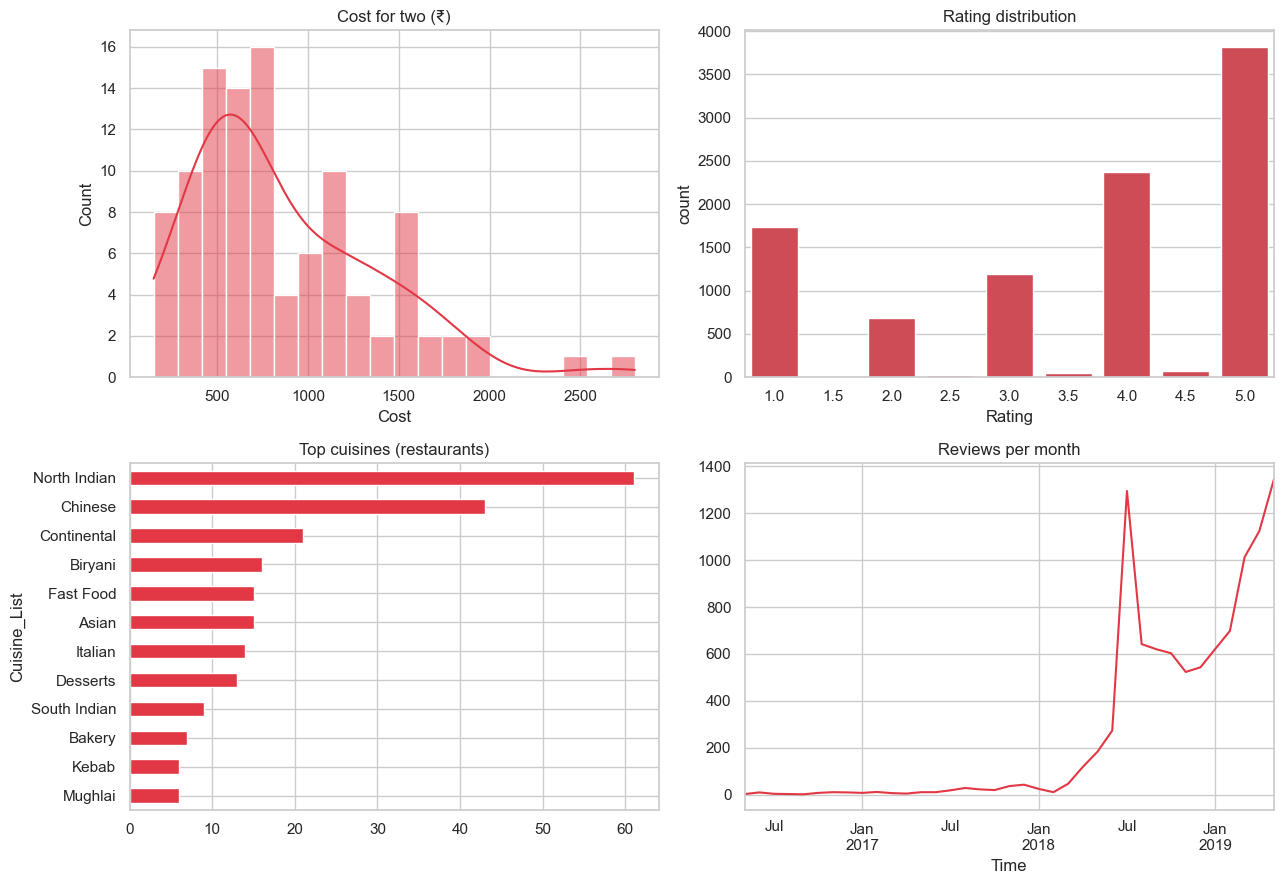

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(meta['Cost'], bins=20, kde=True, ax=ax[0,0], color="#E23744"); ax[0,0].set_title("Cost for two (₹)")
sns.countplot(x=reviews['Rating'], ax=ax[0,1], color="#E23744"); ax[0,1].set_title("Rating distribution")
cu = meta['Cuisine_List'].explode().value_counts().head(12).sort_values()
cu.plot.barh(ax=ax[1,0], color="#E23744"); ax[1,0].set_title("Top cuisines (restaurants)")
m = reviews.groupby(reviews['Time'].dt.to_period('M').dt.to_timestamp()).size()
m.plot(ax=ax[1,1], color="#E23744"); ax[1,1].set_title("Reviews per month")
plt.tight_layout(); plt.show()

**Insights:** cost is right-skewed with most restaurants around ₹500–1,000; ratings are strongly skewed positive
(many 5★), which is why sentiment classes are imbalanced; North Indian and Chinese dominate the cuisine mix; review
volume is concentrated in 2018–2019. *Business impact:* a skewed-positive rating scale means raw averages hide
differences — comparing the share of *negative* reviews is more informative for service quality.

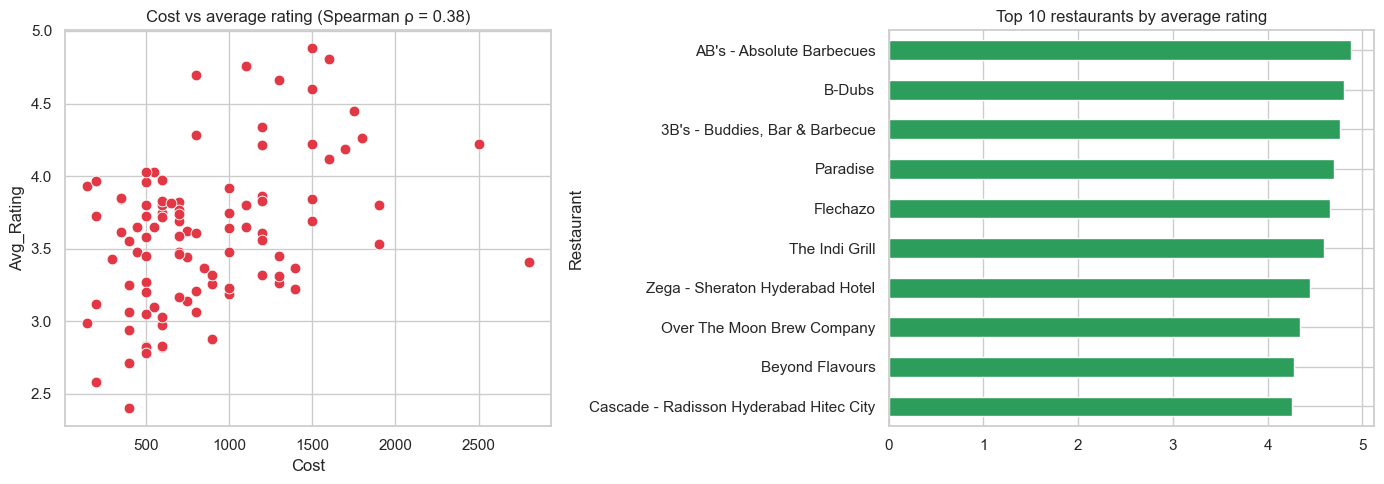

In [10]:
top = reviews.groupby('Restaurant').agg(Avg_Rating=('Rating','mean')).join(meta.set_index('Restaurant')['Cost'])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=top, x='Cost', y='Avg_Rating', ax=ax[0], color="#E23744", s=60)
ax[0].set_title(f"Cost vs average rating (Spearman ρ = {top['Cost'].corr(top['Avg_Rating'], method='spearman'):.2f})")
reviews.groupby('Restaurant')['Rating'].mean().sort_values().tail(10).plot.barh(ax=ax[1], color="#2d9d5c")
ax[1].set_title("Top 10 restaurants by average rating"); plt.tight_layout(); plt.show()

In [11]:
# Influential reviewers: activity vs reach
rv = reviews.groupby('Reviewer').agg(Reviews_in_sample=('Rating','size'),
                                     Followers=('Reviewer_Followers','max'),
                                     Avg_Rating_Given=('Rating','mean'))
display(rv.nlargest(5, 'Followers').round(2))
print("Median rating given by high-reach reviewers (>1000 followers):",
      round(rv.loc[rv['Followers']>1000,'Avg_Rating_Given'].median(),2),
      "vs everyone:", round(rv['Avg_Rating_Given'].median(),2))

,Reviews_in_sample,Followers,Avg_Rating_Given
Reviewer,,,
Satwinder Singh,3,13410.0,3.67
Eat_vth_me,1,13320.0,5.00
Samar Sardar,2,11329.0,3.50
Foodies Hyderabad,4,9494.0,4.50
Srinivas,6,7628.0,4.17


Median rating given by high-reach reviewers (>1000 followers): 4.0 vs everyone: 4.0


## 5. Sentiment classification
**Labels:** ≥4★ → positive, ≤2★ → negative; 2.5–3.5★ are ambiguous and excluded from training.  
**No leakage:** TF-IDF lives inside the `Pipeline`, so it is fit only on training data.  
**Models compared:** Logistic Regression, calibrated Linear SVM, Complement Naive Bayes; then GridSearchCV
(n-gram range, `min_df`, `C`) on Logistic Regression with 5-fold CV optimising F1.

In [12]:
sent_model, sent_report = train_sentiment(reviews)
cmp_df = pd.DataFrame(sent_report['comparison']).round(3)
print(f"Train {sent_report['n_train']:,} / test {sent_report['n_test']:,} | majority baseline accuracy = {sent_report['majority_baseline_accuracy']:.3f}")
display(cmp_df)
print("Best params:", sent_report['best_params'])

Train 6,945 / test 1,737 | majority baseline accuracy = 0.721


,model,stage,accuracy,precision,recall,f1,roc_auc,cv_f1_train
0,Logistic Regression,default,0.948,0.982,0.946,0.963,0.988,0.965
1,Linear SVM (calibrated),default,0.956,0.976,0.962,0.969,0.989,0.969
2,Complement Naive Bayes,default,0.945,0.956,0.968,0.962,0.986,0.959
3,Logistic Regression,tuned,0.952,0.980,0.953,0.966,0.988,0.968


Best params: {'clf__C': '10', 'tfidf__min_df': '1', 'tfidf__ngram_range': '(1, 2)'}


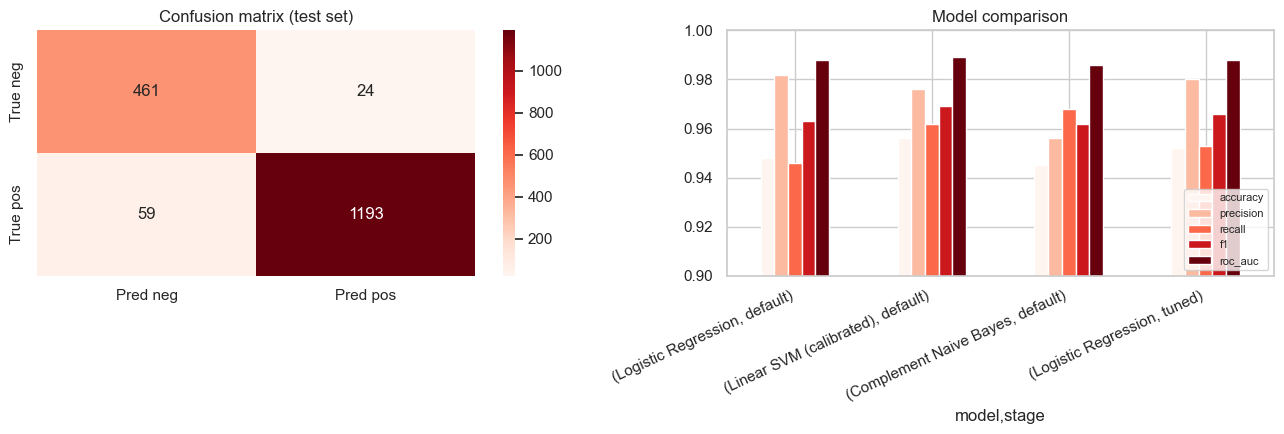

Words pushing NEGATIVE: not, worst, bad, pathetic, no, poor, dont, horrible, disappointed, waste, stale, ordered
Words pushing POSITIVE: best, great, awesome, amazing, try, nice, love, delicious, loved, very good, place, excellent


In [13]:
cm = np.array(sent_report['confusion_matrix'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=ax[0], xticklabels=['Pred neg','Pred pos'], yticklabels=['True neg','True pos'])
ax[0].set_title("Confusion matrix (test set)")
cmp_df.set_index(['model','stage'])[['accuracy','precision','recall','f1','roc_auc']].plot.bar(ax=ax[1], colormap='Reds')
ax[1].set_ylim(0.9, 1.0); ax[1].set_title("Model comparison"); ax[1].legend(loc='lower right', fontsize=8)
plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()
print("Words pushing NEGATIVE:", ", ".join(sent_report['top_negative_words'][:12]))
print("Words pushing POSITIVE:", ", ".join(sent_report['top_positive_words'][:12]))

**Reading the metrics for the business:**
- **Precision (~0.98)** – of reviews flagged positive, almost all truly are → safe to feature/promote.
- **Recall (~0.95)** – we catch most genuinely positive reviews.
- **ROC-AUC (~0.99)** – the score separates the classes well at any threshold; the threshold can be tuned
  (e.g. lower it to catch more complaints).
- **Caveat:** labels come from star ratings, so the model learns rating-style language. Its value is scoring text
  that has *no* star rating (social posts, support chats). Negations (`not`, `no`) are retained and show up among the
  strongest negative words, which validates the preprocessing change.

## 6. Restaurant-level features

In [14]:
reviews["Sentiment_Prob"] = score_reviews(reviews, sent_model)   # out-of-fold probabilities for labelled reviews
rest = build_restaurant_table(meta, reviews)
print(f"{len(rest)} restaurants with reviews | {len(rest.attrs['cuisine_cols'])} cuisine flags (cuisines appearing in >=3 restaurants)")
rest[['Restaurant','Cost','Total_Cuisine_Count','Collection_Count','Opens_Late','Avg_Rating','Pct_Positive','Avg_Pictures']].head()

100 restaurants with reviews | 24 cuisine flags (cuisines appearing in >=3 restaurants)


,Restaurant,Cost,Total_Cuisine_Count,Collection_Count,Opens_Late,Avg_Rating,Pct_Positive,Avg_Pictures
0,Beyond Flavours,800,6,6,0,4.28,0.83,0.39
1,Paradise,800,3,1,0,4.70,0.96,0.02
2,Flechazo,1300,4,2,0,4.66,0.93,0.55
3,Shah Ghouse Hotel & Restaurant,800,5,1,1,3.21,0.52,0.30
4,Over The Moon Brew Company,1200,5,5,1,4.34,0.90,0.44


**Why out-of-fold probabilities?** Using in-sample predictions would let the model "see" the reviews it was trained on,
inflating restaurant sentiment features. **Why is `Avg_Sentiment` not a clustering input?** The sentiment model is
trained on ratings, so it is a near-duplicate of `Avg_Rating`; it is kept only for profiling.

In [15]:
# The original notebook's key flaw: unscaled Cost dominates PCA. Demonstrate it, then show the fix.
cuis = rest[rest.attrs['cuisine_cols']].to_numpy(float)
raw = np.column_stack([rest['Cost'], cuis])
print("UNSCALED  -> PC1 explains {:.3%} of variance".format(PCA().fit(raw).explained_variance_ratio_[0]))
X, scaler, feat_names = build_feature_matrix(rest)
print("SCALED    -> PC1 explains {:.1%}, PC1+PC2 {:.1%}".format(*(lambda r:(r[0], r[:2].sum()))(PCA().fit(X).explained_variance_ratio_)))

UNSCALED  -> PC1 explains 99.999% of variance
SCALED    -> PC1 explains 34.8%, PC1+PC2 51.9%


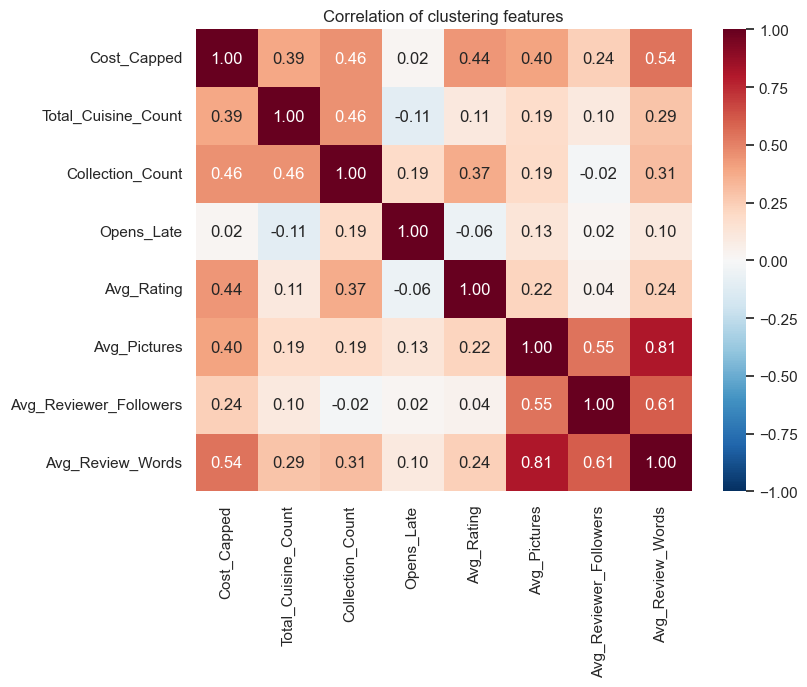

In [16]:
corr = rest[NUMERIC_FEATURES].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation of clustering features"); plt.show()

## 7. Clustering
Three algorithms (KMeans, Ward agglomerative, Gaussian mixture) × k = 2…8 are compared on silhouette (higher better),
Davies-Bouldin (lower better) and Calinski-Harabasz (higher better). A solution is **eligible** only if k ≥ 3 and every
cluster has ≥ 8% of restaurants — this prevents "k=2" or "one tiny outlier cluster" winning on silhouette alone.

In [17]:
grid, best = evaluate_clustering(X)
display(grid.round(3).sort_values('silhouette', ascending=False).head(10))
print("Selected:", best['algorithm'], "k =", int(best['k']))

,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_share,eligible
0,KMeans,2,0.228,1.683,32.753,0.44,False
1,KMeans,3,0.225,1.617,26.884,0.15,True
5,KMeans,7,0.199,1.543,19.440,0.06,False
4,KMeans,6,0.190,1.626,20.264,0.05,False
6,KMeans,8,0.182,1.462,18.671,0.06,False
7,Agglomerative (Ward),2,0.178,1.706,27.453,0.39,False
3,KMeans,5,0.177,1.701,22.001,0.14,True
2,KMeans,4,0.174,1.646,23.341,0.13,True
9,Agglomerative (Ward),4,0.171,1.822,20.821,0.11,True
8,Agglomerative (Ward),3,0.164,1.879,24.208,0.30,True


Selected: KMeans k = 3


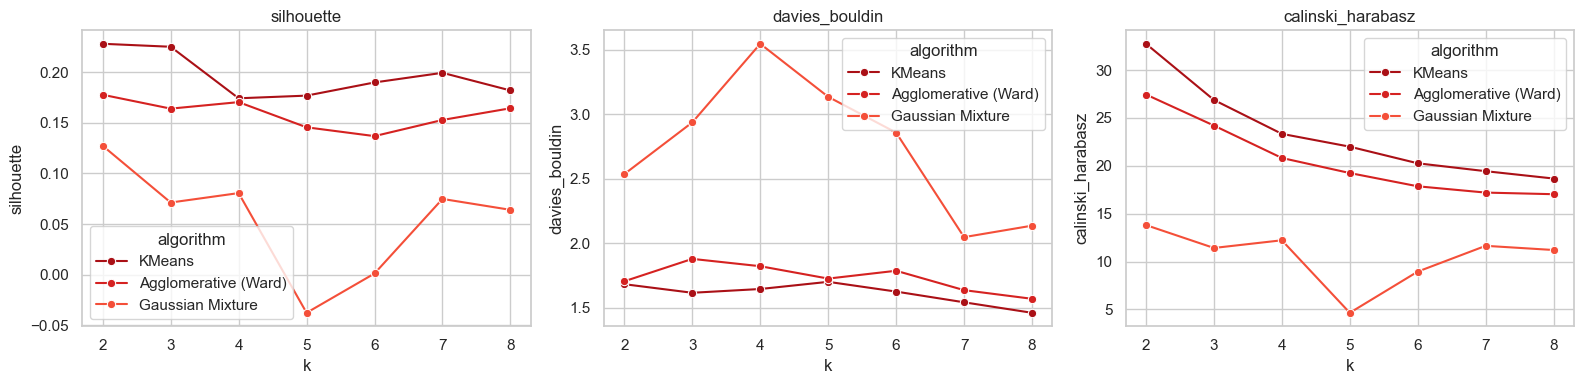

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for metric, a in zip(['silhouette', 'davies_bouldin', 'calinski_harabasz'], ax):
    sns.lineplot(data=grid, x='k', y=metric, hue='algorithm', marker='o', ax=a); a.set_title(metric)
plt.tight_layout(); plt.show()

In [19]:
k = int(best['k'])
rest['Cluster'] = _fit_algo(best['algorithm'], k, X)
names = name_clusters(rest); rest['Cluster_Name'] = rest['Cluster'].map(names)
stab = kmeans_stability(X, k)
print(f"Bootstrap stability (mean ARI over 30 resamples): {stab:.2f}")
print(rest['Cluster_Name'].value_counts().to_string())

Bootstrap stability (mean ARI over 30 resamples): 0.73
Cluster_Name
Budget · Lower-rated · Biryani         48
Mid-range · Well-rated · Sushi         37
Premium · Top-rated · Mediterranean    15


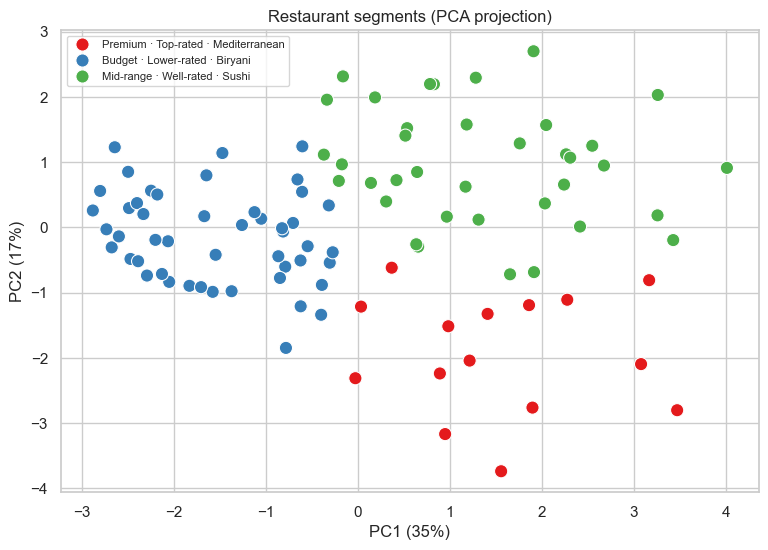

In [20]:
pca = PCA(2, random_state=42).fit(X); xy = pca.transform(X)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=xy[:,0], y=xy[:,1], hue=rest['Cluster_Name'], s=90, palette='Set1')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.title("Restaurant segments (PCA projection)"); plt.legend(fontsize=8, loc='best'); plt.show()

### Cluster profiles — the part that makes clustering useful

In [21]:
prof = rest.groupby('Cluster_Name').agg(
    Restaurants=('Restaurant','size'), Median_Cost=('Cost','median'), Avg_Rating=('Avg_Rating','mean'),
    Pct_Positive=('Pct_Positive','mean'), Avg_Cuisines=('Total_Cuisine_Count','mean'),
    Late_Night=('Opens_Late','mean'), Collections=('Collection_Count','mean'), Followers=('Avg_Reviewer_Followers','mean')).round(2)
display(prof)
sig = signature_cuisines(rest)
for c, n in names.items():
    ex = rest[rest['Cluster']==c].nlargest(4, 'Avg_Rating')['Restaurant'].tolist()
    print(f"{n}\n   signature cuisines: {sig[c]}\n   top-rated examples: {ex}")

,Restaurants,Median_Cost,Avg_Rating,Pct_Positive,Avg_Cuisines,Late_Night,Collections,Followers
Cluster_Name,,,,,,,,
Budget · Lower-rated · Biryani,48,500.0,3.39,0.61,2.65,0.40,0.42,20.73
Mid-range · Well-rated · Sushi,37,1000.0,3.64,0.75,3.14,0.35,0.84,109.94
Premium · Top-rated · Mediterranean,15,1300.0,4.20,0.85,3.87,0.60,3.60,34.27


Budget · Lower-rated · Biryani
   signature cuisines: ['Biryani', 'South Indian']
   top-rated examples: ['Paradise', "Udipi's Upahar", 'KS Bakers', "GD's"]
Mid-range · Well-rated · Sushi
   signature cuisines: ['Sushi', 'Cafe']
   top-rated examples: ['Zega - Sheraton Hyderabad Hotel', 'Cascade - Radisson Hyderabad Hitec City', 'Barbeque Nation', 'Arena Eleven']
Premium · Top-rated · Mediterranean
   signature cuisines: ['Mediterranean', 'European']
   top-rated examples: ["AB's - Absolute Barbecues", 'B-Dubs', "3B's - Buddies, Bar & Barbecue", 'Flechazo']


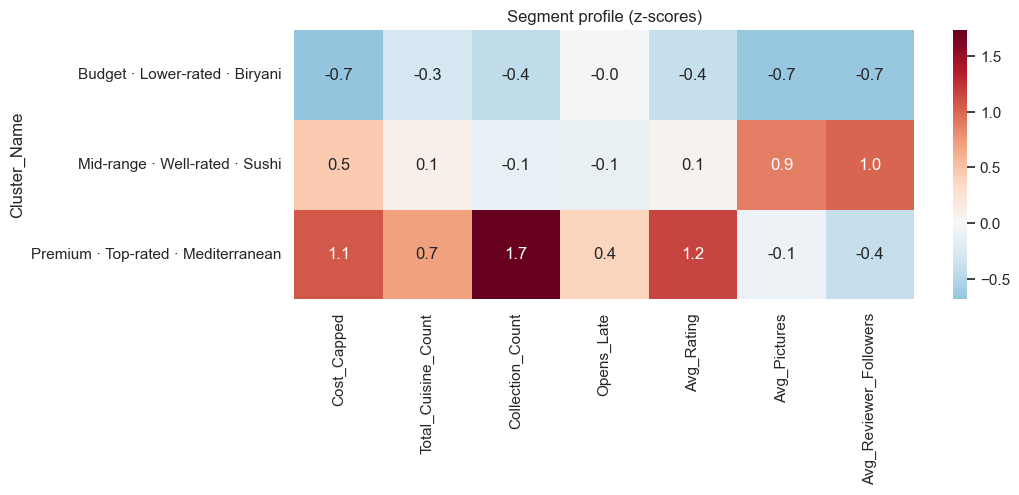

In [22]:
z = rest.groupby('Cluster_Name')[['Cost_Capped','Total_Cuisine_Count','Collection_Count','Opens_Late','Avg_Rating','Avg_Pictures','Avg_Reviewer_Followers']].mean()
z = (z - rest[z.columns].mean()) / rest[z.columns].std()
plt.figure(figsize=(10, 3.5)); sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0); plt.title("Segment profile (z-scores)"); plt.show()

### Honest Asessment
Silhouette ≈ 0.22 means **moderate, overlapping** structure. With 100 restaurants, and variation driven mostly by price,
this is realistic; a much higher number would signal an artefact (as the unscaled `Cost` version showed). Bootstrap ARI ≈ 0.7
says segments are reasonably reproducible. Use them as **market tiers**, not hard categories.

**Business use:** price-tier benchmarks for pricing decisions, targeted promotions (premium segment has the most Zomato
collections), and an underperformance watch-list (budget segment has the lowest share of positive reviews).

## 8. What do customers talk about? (topic modelling)

In [23]:
topics = {"negative (<=2 stars)": extract_topics(reviews.loc[reviews['Rating'] <= 2, 'Clean_Review']),
          "positive (>=4.5 stars)": extract_topics(reviews.loc[reviews['Rating'] >= 4.5, 'Clean_Review'])}
for group, ts in topics.items():
    print(f"\n=== {group} ===")
    for t in ts:
        print(f"Theme {t['topic']} ({t['share']:.0%}): {', '.join(t['keywords'][:7])}")


=== negative (<=2 stars) ===
Theme 1 (49%): chicken, no, service, biryani, dont, taste, veg
Theme 2 (20%): not, taste not, delivered, not delivered, taste, tasty, not tasty
Theme 3 (12%): worst, worst experience, worst taste, experience, taste, worst service, life
Theme 4 (6%): quantity, quality, low, quantity not, taste, price, quality quantity
Theme 5 (13%): bad, quality, bad experience, bad quality, taste, experience, delivery

=== positive (>=4.5 stars) ===
Theme 1 (65%): service, great, ambience, best, visit, amazing, staff
Theme 2 (6%): delivery, fast, fast delivery, quick delivery, quick, super, nice delivery
Theme 3 (11%): nice, nice service, nice ambience, service nice, friendly, ambience nice, friends
Theme 4 (11%): awesome, awesome service, awesome taste, taste, guys, awesome delivery, service awesome
Theme 5 (7%): excellent, excellent service, service, service excellent, thank, excellent excellent, excellent delivery


NMF on TF-IDF is used instead of LDA on TF-IDF because LDA expects word *counts* and short reviews give unstable topics.
**Action:** complaints concentrate on taste/quality, order accuracy/delivery and service; delighted customers praise service,
ambience and fast delivery — Zomato can surface these themes to restaurants as improvement dashboards.

## 9. Save artefacts for the Streamlit app

In [24]:
# The full pipeline (identical logic) lives in src/train.py and writes everything the app reads.
import subprocess
out = subprocess.run([sys.executable, str(ROOT / "src" / "train.py")], capture_output=True, text=True)
print(out.stdout[-900:] or out.stderr[-900:])

Metadata (105, 11), reviews (10000, 7) -> (9938, 13) after cleaning (8682 labelled, 1256 neutral)
Sentiment (tuned LR) test: {'accuracy': 0.952, 'precision': 0.98, 'recall': 0.953, 'f1': 0.966, 'roc_auc': 0.988, 'cv_f1_train': 0.968}
Best clustering: KMeans k=3 silhouette=0.225 DB=1.617 stability(ARI)=0.726
Artifacts written to D:\FAHAD\New folder\Scubel\Data Science\Zomato_Restaurant_Clustering\zomato_project\artifacts



## 10. Conclusion

In [25]:
from IPython.display import Markdown
sizes = rest['Cluster_Name'].value_counts()
tuned = [r for r in sent_report['comparison'] if r['stage']=='tuned'][0]
Markdown(f'''
**Segments.** {len(rest)} restaurants split into {k} tiers — {"; ".join(f"**{n}** ({c})" for n, c in sizes.items())}.
Price, rating and share of positive reviews rise together across tiers (silhouette {best['silhouette']:.2f}, bootstrap ARI {stab:.2f}).

**Sentiment.** A tuned TF-IDF + Logistic Regression pipeline reaches F1 **{tuned['f1']:.3f}**, precision {tuned['precision']:.3f},
recall {tuned['recall']:.3f}, ROC-AUC {tuned['roc_auc']:.3f} on held-out reviews (baseline accuracy {sent_report['majority_baseline_accuracy']:.2f}).

**Themes.** Unhappy reviews centre on taste/quality, delivery/order accuracy and service; happy ones on service, ambience and fast delivery.

**Limits.** Only 100 restaurants in one city; sentiment labels derive from ratings; clusters are moderate, not sharp.
**Next steps:** add geography/area features, multi-city data, a 3-class sentiment model with human-labelled neutrals,
and time-aware drift monitoring.
''')


**Segments.** 100 restaurants split into 3 tiers — **Budget · Lower-rated · Biryani** (48); **Mid-range · Well-rated · Sushi** (37); **Premium · Top-rated · Mediterranean** (15).
Price, rating and share of positive reviews rise together across tiers (silhouette 0.23, bootstrap ARI 0.73).

**Sentiment.** A tuned TF-IDF + Logistic Regression pipeline reaches F1 **0.966**, precision 0.980,
recall 0.953, ROC-AUC 0.988 on held-out reviews (baseline accuracy 0.72).

**Themes.** Unhappy reviews centre on taste/quality, delivery/order accuracy and service; happy ones on service, ambience and fast delivery.

**Limits.** Only 100 restaurants in one city; sentiment labels derive from ratings; clusters are moderate, not sharp.
**Next steps:** add geography/area features, multi-city data, a 3-class sentiment model with human-labelled neutrals,
and time-aware drift monitoring.
